# Plotting Data
Although there are multiple open-source Python libraries that are focused on plotting data, the classic one when we talk about Python, and perhaps the most beginner-friendly one, is Matplotlib!

Based on Chapter 4 of the "Python Data Science Handbook" book by Jake VanderPlas
URL: https://jakevdp.github.io/PythonDataScienceHandbook/

In [44]:
import matplotlib.pyplot as plt
import numpy as np

## 0. 2D Plots

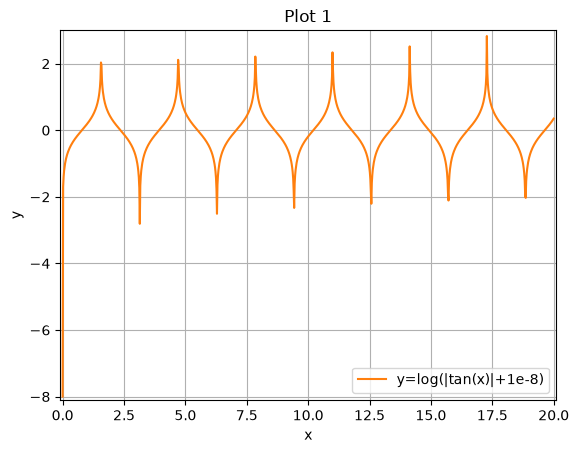

In [45]:
#here's how to create simple 2D (line) plots

plt.figure() #start by creating a figure object
x = np.linspace(0, 20, 1000) #define a linearly-spaced array to act as our input domain
y = np.log10(np.abs(np.tan(x))+1e-8) #create any function you want
plt.plot(x,y, color='tab:orange', label="y=log(|tan(x)|+1e-8)") #plot y as a function of x, or f(x)
#the first value is usually the x-axis variables
#the second value is usually the y-axis variables
#color is the which color the function will be plotted
#label is the text that will be displayed on the legend of the plot
plt.xlabel("x") #label of the x-axis
plt.ylabel("y") #label of the y-axis
plt.xlim([x[0]-0.1, x[-1]+0.1]) #limits the x-axis of the plot
plt.ylim([-8.1, 3]) #limits the y-axis of the plot
plt.legend(loc="lower right") #display the legend of the plot ("loc" is the location in the plot)
plt.title("Plot 1") #add a title to the plot
plt.grid() #grid on the plot
plt.show() #disply the plot

Sometimes, we want to plot only the points instead of the whole interpolated curve:

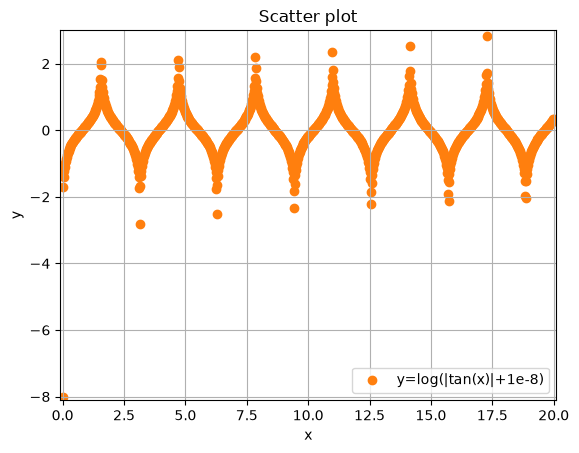

In [46]:
plt.figure() #start by creating a figure object
plt.scatter(x,y, color='tab:orange', label="y=log(|tan(x)|+1e-8)") #plot y as a function of x, or f(x)
plt.xlabel("x") #label of the x-axis
plt.ylabel("y") #label of the y-axis
plt.xlim([x[0]-0.1, x[-1]+0.1]) #limits the x-axis of the plot
plt.ylim([-8.1, 3]) #limits the y-axis of the plot
plt.legend(loc="lower right") #display the legend of the plot ("loc" is the location in the plot)
plt.title("Scatter plot") #add a title to the plot
plt.grid() #grid on the plot
plt.show() #disply the plot

Plots can be overlapped with other functions as well:

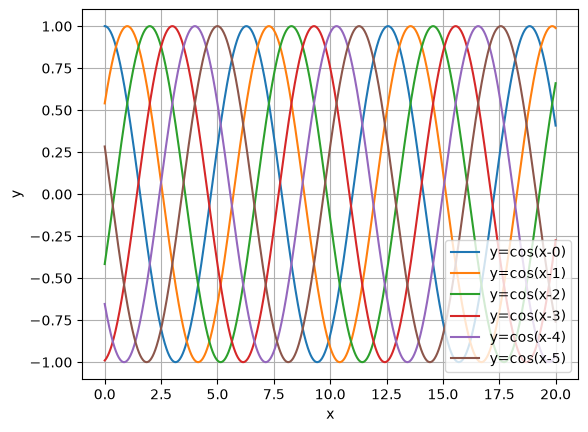

In [47]:
plt.figure()
offsets = np.arange(0,6,1) #create arbitray offsets in the functions
for i in offsets:
    plt.plot(x, np.cos(x-i), label=f"y=cos(x-{i})")
plt.xlabel("x")
plt.ylabel("y")
plt.legend(loc="lower right") #display the legend of the plot ("loc" is the location in the plot)
plt.grid() #grid on the plot
plt.show() #disply the plot

Or plotted separately as subplots:

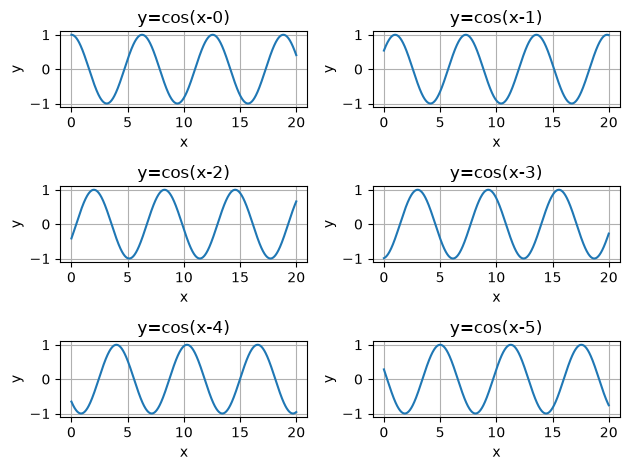

In [48]:
plt.figure()
n_rows = 3 #define the number of rows
n_cols = 2 #define the number of columns
for i in offsets:
    plt.subplot(n_rows, n_cols, i+1) #defining subplots(n_rows, n_cols, index)
    plt.plot(x, np.cos(x-i))
    plt.xlabel("x")
    plt.ylabel("y")
    plt.title(f"y=cos(x-{i})")
    plt.grid() #grid on the plot
plt.tight_layout() 
plt.show() #disply the plot

## 1. 3D Plots

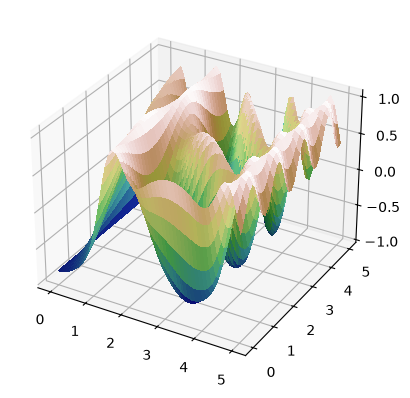

In [49]:
#create 3D data
x = np.linspace(0, 5, 50)
y = np.linspace(0, 5, 40)
X, Y = np.meshgrid(x, y) #create a mesh with all values of x and y
f = lambda x,y: np.sin(x)**10 + np.cos(10 + y*x)*np.cos(x) #create a function that operates in all points of our domain
Z = f(X,Y) #compute the lambda function over the 2D domain

#"custom hillshading mode" example
# https://matplotlib.org/stable/gallery/mplot3d/custom_shaded_3d_surface.html
from matplotlib import cbook
from matplotlib.colors import LightSource

fig, ax = plt.subplots(subplot_kw=dict(projection='3d')) #creates a subplot object with 3D projection
ls = LightSource(270, 45)
rgb = ls.shade(Z, cmap=plt.colormaps["gist_earth"], vert_exag=0.1, blend_mode='soft')
surf = ax.plot_surface(X, Y, Z, rstride=1, cstride=1, facecolors=rgb,
                       linewidth=0, antialiased=False, shade=False)
plt.show()

## 2. Contour and "Heatmap" plots
Sometimes it is useful to display three-dimensional data in two dimensions using contours or color-coded regions.

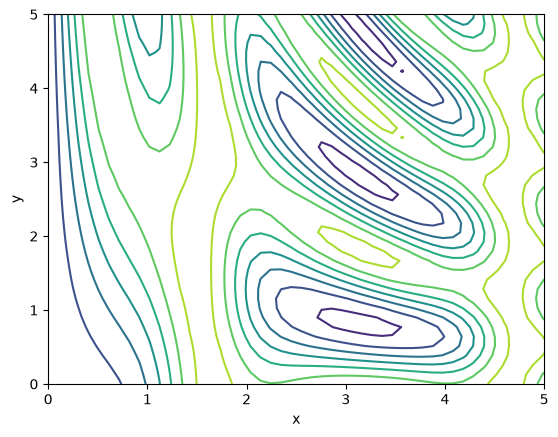

In [50]:
#contour plot
plt.figure()
plt.contour(X, Y, Z)
plt.xlabel("x")
plt.ylabel("y")
plt.show()

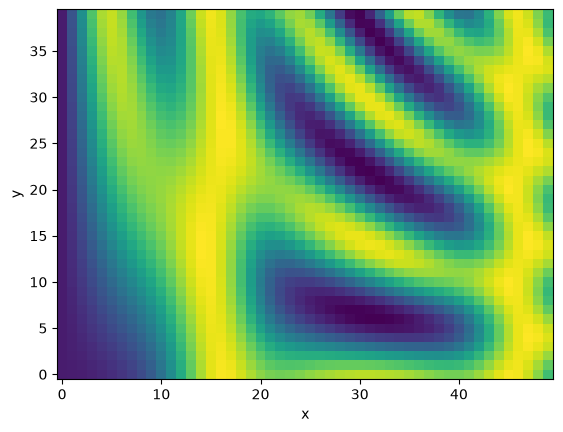

In [51]:
#"heatmap"
plt.figure()
plt.imshow(Z, origin='lower', aspect="auto")
plt.xlabel("x")
plt.ylabel("y")
plt.show()